# Repaso práctico · Clasificación y regresión

**20 ejercicios + 8 preguntas breves.** Nivel básico de repaso.

1. Desarrollo de un modelo.
2. KNN, random forest y naive Bayes.
3. OvO, OvR, GridSearchCV e imbalanced-learn.
4. De clasificación a regresión.
5. Regresión lineal, KNN, árbol y random forest.

Completa los `...`, añade lo que falta y corrige las celdas marcadas.
Responde las preguntas en una o dos frases. Ejecuta de arriba abajo **después de completar cada ejercicio**.
Las celdas de preparación se ejecutan tal cual. Los datos no necesitan descargas.

Borja Fernández Antelo · [borjafernandez.es](https://borjafernandez.es)

**Versión de alumnado · Sin respuestas.**

## Preparación

Si falta alguna librería, descomenta y ejecuta esta celda. Después, reinicia el kernel.
`imbalanced-learn` se instala con ese nombre y se importa como `imblearn`.

In [ ]:
# %pip install numpy pandas scikit-learn imbalanced-learn

In [2]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris, make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, recall_score, mean_absolute_error

## 1 · Pasos de desarrollo de un modelo

Caso: identificar una especie de flor a partir de cuatro medidas. Cada fila es una flor.

### Ejercicio 01 · Ordena el proceso

Ordena estas acciones. Escribe las letras en orden.

- A. Ajustar el preprocesado con entrenamiento y entrenar/ajustar modelos con validación cruzada.
- B. Definir qué predecir y cómo medir el éxito.
- C. Evaluar el modelo elegido con el test reservado.
- D. Recoger los datos y comprobar su calidad.
- E. Separar entrenamiento y test antes de aprender transformaciones.
- F. Poner el modelo en uso y vigilar su rendimiento.
- G. Explorar los datos de entrenamiento: distribuciones, nulos y clases.

**Tu respuesta:** …

**Preparación · Iris**

In [ ]:
iris = load_iris(as_frame=True)
flores = iris.frame
display(flores.head(3))

### Ejercicio 02 · Separa entradas, objetivo y test

Separa variables de entrada y salida.
Reserva un 25 % para test.
Conserva aproximadamente las proporciones de las clases.

In [ ]:
Xc = flores.drop(columns=...)
yc = flores[...]
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=..., random_state=42, stratify=...
)
print(Xc_train.shape, Xc_test.shape)

### Ejercicio 03 · Corrige el escalado

**Código con dos fallos.** El escalador aprende de todos los datos y vuelve a aprender del test.
Corrige las dos llamadas para que solo aprenda de entrenamiento.

In [ ]:
escala = StandardScaler()
escala.fit(Xc)
Xc_train_s = escala.transform(Xc_train)
Xc_test_s = escala.fit_transform(Xc_test)
print(Xc_train_s.shape, Xc_test_s.shape)

### Pregunta 1

Un compañero entrena y evalúa con todas las filas de un DataFrame. Obtiene un 100 % de acierto. ¿Qué falta para saber si generaliza?

**Tu respuesta:** …

## 2 · KNN, random forest y naive Bayes

Usaremos el mismo reparto de Iris. Los parámetros de este bloque ya están fijados:
el test sirve para comprobarlos, no para ir cambiándolos hasta mejorar su resultado.

### Ejercicio 04 · Completa KNN y detecta qué falta

Usa 5 vecinos. Falta una línea entre la creación del modelo y la predicción: añádela.
Utiliza las entradas escaladas del ejercicio 3.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=...)
# Añade aquí la línea que falta.
pred_knn = knn.predict(Xc_test_s)
print('Accuracy:', round(accuracy_score(..., pred_knn), 3))

### Pregunta 2

Con KNN y pesos uniformes, los tres vecinos más cercanos tienen clases A, A y B. ¿Qué predice? ¿Por qué importa escalar las variables?

**Tu respuesta:** …

### Ejercicio 05 · Completa random forest

Crea 80 árboles y limita su profundidad a 4. Entrena y predice.
¿Qué usarías aquí? ¿Las entradas originales o los datos escalados?

In [ ]:
from sklearn.ensemble import RandomForestClassifier
bosque = RandomForestClassifier(...=..., ...=..., random_state=42)
bosque.fit(..., ...)
pred_bosque = bosque.predict(...)
print('Accuracy:', round(accuracy_score(yc_test, pred_bosque), 3))

### Pregunta 3

¿Por qué un random forest no suele producir muchos árboles idénticos? Menciona las dos fuentes habituales de aleatoriedad.

**Tu respuesta:** …

### Ejercicio 06 · Completa naive Bayes

Usa `GaussianNB` para estas medidas numéricas. Completa el entrenamiento y la predicción.

In [ ]:
from sklearn.naive_bayes import GaussianNB
bayes = GaussianNB()
bayes.fit(..., ...)
pred_bayes = bayes.predict(...)
print('Accuracy:', round(accuracy_score(yc_test, pred_bayes), 3))

### Pregunta 4

¿Qué simplificación hace naive Bayes sobre las variables? ¿Qué añade la variante GaussianNB?

**Tu respuesta:** …

## 3 · OvO, OvR, GridSearchCV e imblearn

OvO enfrenta pares de clases. OvR enfrenta cada clase contra el resto.
GridSearchCV prueba combinaciones de hiperparámetros con validación cruzada.

### Ejercicio 07 · Cuenta los clasificadores

Hay cuatro clases: A, B, C y D.

- OvR: ___ clasificadores. Escribe uno de los enfrentamientos.
- OvO: ___ clasificadores. Escribe todos los pares, sin repetirlos.

**Tu respuesta:** …

### Ejercicio 08 · Aplica ambas estrategias

Completa con `OneVsRestClassifier` y `OneVsOneClassifier`.
GaussianNB ya admite varias clases; lo envolvemos solo para practicar las dos estrategias.

In [ ]:
from sklearn.multiclass import OneVsRestClassifier, OneVsOneClassifier
ovr = ...(GaussianNB())
ovo = ...(GaussianNB())
ovr.fit(Xc_train, yc_train)
ovo.fit(Xc_train, yc_train)
print('Modelos OvR:', len(ovr.estimators_))
print('Modelos OvO:', len(ovo.estimators_))

### Ejercicio 09 · Completa GridSearchCV

Prueba `k = 3, 5, 7` y pesos `uniform` / `distance`, con 3 particiones.
La pipeline aprende el escalado dentro de cada partición. Ajusta la búsqueda solo con entrenamiento.

In [ ]:
from sklearn.model_selection import GridSearchCV
pipe_knn = Pipeline([('escala', StandardScaler()), 
                     ('knn', KNeighborsClassifier())])
rejilla = {'knn__n_neighbors': ..., 'knn__weights': ...}
busqueda = GridSearchCV(pipe_knn, 
                        rejilla, 
                        cv=..., 
                        scoring='accuracy')
busqueda.fit(..., ...)
print(busqueda.best_params_)
print('Accuracy media de validación:', round(busqueda.best_score_, 3))

In [ ]:
from sklearn.model_selection import GridSearchCV
pipe_knn = Pipeline([('escala', StandardScaler()), 
                     ('knn', KNeighborsClassifier())])
rejilla = {'knn__n_neighbors': ..., 'knn__weights': ...}
busqueda = GridSearchCV(pipe_knn, 
                        rejilla, 
                        cv=..., #################¿y cómo hacemos para que sea stratificada?
                        scoring='accuracy')
busqueda.fit(..., ...)
print(busqueda.best_params_)
print('Accuracy media de validación:', round(busqueda.best_score_, 3))

### Pregunta 5

Hay 6 combinaciones y cv=3. ¿Cuántos entrenamientos se hacen durante la búsqueda? Con refit=True, ¿cuántos hay en total? ¿Interviene el test?

**Tu respuesta:** …

### Ejercicio 10 · Detecta una métrica engañosa

La clase 1 es la minoritaria. Un modelo siempre predice 0.
Completa las dos métricas y observa si detecta algún caso de la clase 1.

In [ ]:
reales = [0] * 95 + [1] * 5
pred_mayoria = [0] * 100
print('Accuracy:', ...(reales, pred_mayoria))
print('Recall clase 1:', ...(reales, pred_mayoria, zero_division=0))

**Preparación · Datos desbalanceados**

`SMOTE` crea ejemplos sintéticos de la clase minoritaria interpolando entre vecinos.
Este ejemplo contiene solo variables numéricas. El test conserva la distribución original.

In [5]:
from imblearn.over_sampling import SMOTE
from collections import Counter
Xi, yi = make_classification(
    n_samples=400, n_features=4, n_informative=3, n_redundant=0,
    weights=[0.9, 0.1], random_state=42
)
Xi_train, Xi_test, yi_train, yi_test = train_test_split(
    Xi, yi, test_size=0.25, stratify=yi, random_state=42
)
print('Entrenamiento:', Counter(yi_train.tolist()), '| Test:', Counter(yi_test.tolist()))

Entrenamiento: Counter({0: 271, 1: 29}) | Test: Counter({0: 91, 1: 9})


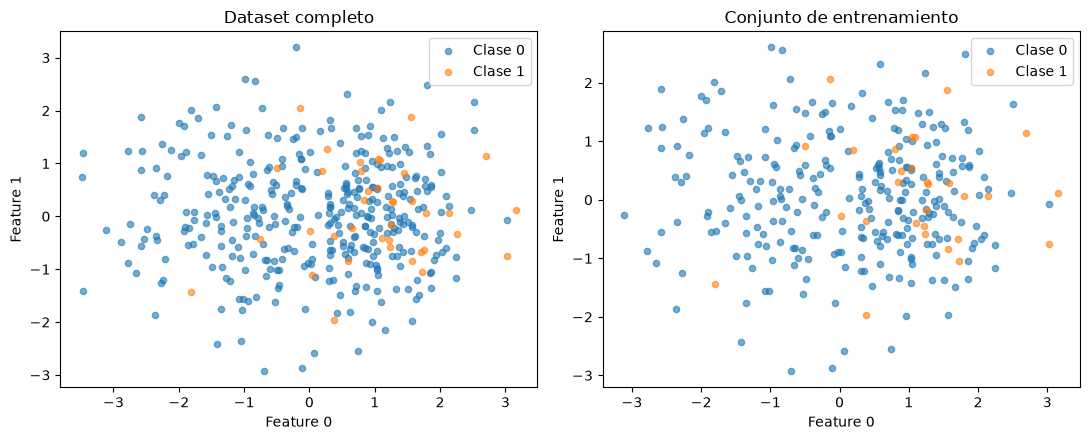

In [4]:
import matplotlib.pyplot as plt
from collections import Counter

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Dataset completo
axes[0].scatter(Xi[yi == 0, 0], Xi[yi == 0, 1],
                s=20, alpha=0.6, label='Clase 0')
axes[0].scatter(Xi[yi == 1, 0], Xi[yi == 1, 1],
                s=20, alpha=0.6, label='Clase 1')
axes[0].set_title('Dataset completo')
axes[0].set_xlabel('Feature 0')
axes[0].set_ylabel('Feature 1')
axes[0].legend()

# Solo entrenamiento
axes[1].scatter(Xi_train[yi_train == 0, 0], Xi_train[yi_train == 0, 1],
                s=20, alpha=0.6, label='Clase 0')
axes[1].scatter(Xi_train[yi_train == 1, 0], Xi_train[yi_train == 1, 1],
                s=20, alpha=0.6, label='Clase 1')
axes[1].set_title('Conjunto de entrenamiento')
axes[1].set_xlabel('Feature 0')
axes[1].set_ylabel('Feature 1')
axes[1].legend()

plt.tight_layout()
plt.show()

### Ejercicio 11 · Corrige dónde se aplica SMOTE

**Código con fallo.** Cambia los argumentos de `fit_resample`: ¿Dónde se debe remuestrear?
Esta celda permite ver los recuentos; en el siguiente ejercicio usaremos una pipeline para validación cruzada.

In [ ]:
smote = SMOTE(random_state=42)
Xi_bal, yi_bal = smote.fit_resample(Xi_test, yi_test)
print('Antes:', Counter(yi_train.tolist()))
print('Después:', Counter(yi_bal.tolist()))

### Ejercicio 12 · Mete SMOTE dentro de la validación

Usa `imblearn.pipeline.Pipeline`: admite pasos de remuestreo.
Completa el paso SMOTE y los datos de entrenamiento **originales**, sin remuestrear.
Aquí se elige `k` por recall; mejorar esta métrica no garantiza mejorar todas las demás.

In [ ]:
from imblearn.pipeline import Pipeline as ImbPipeline
pipe_smote = ImbPipeline([
    ('escala', StandardScaler()),
    ('smote', ...),
    ('knn', KNeighborsClassifier())
])
ajuste_smote = GridSearchCV(
    ..., {'knn__n_neighbors': [3, 5]}, cv=3, scoring='recall'
)
ajuste_smote.fit(..., ...);

**Comprobación · Test original, sin remuestrear**

In [ ]:
pred_smote = ajuste_smote.predict(Xi_test)
print('Mejor k:', ajuste_smote.best_params_)
print('Accuracy:', round(accuracy_score(yi_test, pred_smote), 3))
print('Recall clase 1:', round(recall_score(yi_test, pred_smote), 3))

### Pregunta 6

¿Por qué sería un error usar Xi_bal e yi_bal del ejercicio 11 en GridSearchCV? ¿Qué evita la pipeline del ejercicio 12?

**Tu respuesta:** …

## 4 · De clasificación a regresión

**Misma vivienda, dos preguntas:** «¿consumo bajo, medio o alto?» es clasificación;
«¿cuántos kWh consumirá?» es regresión. Cambia lo que quieres predecir.

| Aspecto | Clasificación | Regresión |
|---|---|---|
| Salida | Una categoría | Una cantidad numérica |
| Ejemplo | Bajo / medio / alto | 245,7 kWh |
| Evaluación habitual | Accuracy, precisión, recall, F1 | MAE, RMSE, R² |
| KNN con pesos uniformes | Voto de los vecinos | Media de sus valores |

**En común:** entradas `X`, objetivo `y`, separación de datos, `fit`, `predict`
y evaluación con datos nuevos. Un `Pipeline` sigue siendo útil.

### Ejercicio 13 · Decide la tarea

Escribe **C** (clasificación) o **R** (regresión) y señala qué sería `y`.

1. Predecir el precio de venta de un coche.
2. Decidir si un correo es spam.
3. Estimar los minutos de espera de un pedido.
4. Determinar la calidad de una valoración de una experiencia en un restaurante como 0=negativa, 1=neutra o 2=positiva.

**Tu respuesta:** …

### Ejercicio 14 · Una recta y un error

Un modelo predice consumo con la recta **ŷ = 50 + 20 × horas**.

- Para 4 horas: predicción = ___ kWh.
- Si el consumo real es 140 kWh: error absoluto = ___ kWh.
- Con errores absolutos de 10, 20 y 0 kWh: MAE = ___ kWh.

**Tu respuesta:** …

### Pregunta 7

¿Codificar las clases como 0, 1 y 2 convierte el problema en regresión? ¿La regresión logística se usa aquí como clasificador o como regresor?

**Tu respuesta:** …

## 5 · Implementa y compara regresores

Caso sintético: predecir consumo mensual en **kWh** a partir de superficie, horas de uso
y temperatura. Son viviendas independientes; usamos un reparto aleatorio.
Las fórmulas generan datos de práctica, no describen un consumo real.

**Preparación · Datos de consumo**

In [ ]:
rng = np.random.default_rng(42)
consumo = pd.DataFrame({
    'm2': rng.uniform(40, 150, 240),
    'horas_uso': rng.uniform(1, 10, 240),
    'temperatura': rng.uniform(5, 30, 240)
})
consumo['kwh'] = (80 + 4 * consumo['m2'] + 35 * consumo['horas_uso']
                  - 3 * consumo['temperatura'] + rng.normal(0, 20, 240))
display(consumo.head(3).round(1))

### Ejercicio 15 · Separa el problema de regresión

Separar X e y. Reserva un 25 % para test.
Necesitamos usar `stratify`?

Conservaremos el test hasta el ejercicio 20.

In [ ]:
Xr = consumo.drop(columns=...)
yr = consumo[...]
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    Xr, yr, test_size=..., random_state=42
)
print(Xr_train.shape, Xr_test.shape)

**Patrón:** crear → entrenar con `fit` → predecir con `predict`.
En los siguientes cuatro ejercicios solo veremos tres predicciones sobre entrenamiento;
todavía no sirven para medir la generalización. Los hiperparámetros ya están fijados.

### Ejercicio 16 · Regresión lineal

Completa el entrenamiento y la predicción de las tres primeras filas de entrenamiento.
Este modelo aprende una suma de variables multiplicadas por coeficientes, más un término independiente.

In [ ]:
from sklearn.linear_model import LinearRegression
lineal = LinearRegression()
lineal.fit(..., ...)
print(lineal.predict(...).round(1))

### Ejercicio 17 · KNN para regresión

Usa `KNeighborsRegressor` con 5 vecinos y añade el escalador que falta en el primer paso.
Con pesos uniformes, predice la media de los valores de los vecinos.

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
knn_r = Pipeline([
    ('escala', ...),
    ('modelo', KNeighborsRegressor(n_neighbors=...))
])
knn_r.fit(Xr_train, yr_train)
print(knn_r.predict(Xr_train.iloc[:3]).round(1))

### Ejercicio 18 · Corrige el árbol

**Código con fallo.** Conserva la profundidad 4.
Con el criterio por defecto, cada hoja predice la media del objetivo de sus filas de entrenamiento.

In [ ]:
from sklearn.tree import DecisionTreeClassifier
arbol_r = DecisionTreeClassifier(max_depth=4, random_state=42)
arbol_r.fit(Xr_train, yr_train)
print(arbol_r.predict(Xr_train.iloc[:3]).round(1))

### Ejercicio 19 · Random forest para regresión

Completa con `RandomForestRegressor`: 80 árboles y profundidad máxima 6.
Su predicción combina las de los árboles mediante una media.

In [ ]:
from sklearn.ensemble import RandomForestRegressor
bosque_r = ...(n_estimators=..., max_depth=..., random_state=42)
bosque_r.fit(Xr_train, yr_train)
print(bosque_r.predict(Xr_train.iloc[:3]).round(1))

In [ ]:
from sklearn.model_selection import cross_val_score, KFold
modelos = {'Lineal': lineal, 'KNN': knn_r,
           'Árbol': arbol_r, 'Random forest': bosque_r}
cv_r = KFold(n_splits=3, shuffle=True, random_state=42)

### Ejercicio 20 · Compara, elige y evalúa

Completa los datos usados en validación cruzada. La puntuación
`neg_mean_absolute_error` devuelve el MAE con signo negativo: cambia el signo de su media.
Gana el menor MAE de validación. Después predice el test con ese modelo y calcula su MAE.

In [ ]:
filas = []
for nombre, modelo in modelos.items():
    scores = cross_val_score(modelo, ..., ..., cv=cv_r,
                             scoring='neg_mean_absolute_error')
    mae_cv = ...
    filas.append({'Modelo': nombre, 'MAE validación (kWh)': mae_cv})
comparacion = pd.DataFrame(filas).sort_values('MAE validación (kWh)')
display(comparacion.round(2))

In [ ]:
elegido = comparacion.iloc[0]['Modelo']
mejor_r = modelos[elegido]
mejor_r.fit(Xr_train, yr_train)
pred_r = mejor_r.predict(...)
mae_test = ...
print('Elegido:', elegido)
print('MAE test (kWh):', round(mae_test, 2))

**Comprobación · Cinco predicciones finales**

In [ ]:
detalle = pd.DataFrame({'Real': yr_test, 'Predicción': pred_r})
detalle['Error absoluto'] = abs(detalle['Real'] - detalle['Predicción'])
display(detalle.head(5).round(1))

---

**Documentación de consulta · Revisión: 29/10/2026 (Europe/Madrid)**

- [Separación, escalado y fuga de datos](https://scikit-learn.org/stable/common_pitfalls.html).
- [KNN: clasificación y regresión](https://scikit-learn.org/stable/modules/neighbors.html).
- [Random forest](https://scikit-learn.org/stable/modules/ensemble.html#forest) y [naive Bayes](https://scikit-learn.org/stable/modules/naive_bayes.html).
- [OvO](https://scikit-learn.org/stable/modules/generated/sklearn.multiclass.OneVsOneClassifier.html), [OvR](https://scikit-learn.org/stable/modules/generated/sklearn.multiclass.OneVsRestClassifier.html) y [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).
- [Remuestreo y fuga de datos](https://imbalanced-learn.org/stable/common_pitfalls.html).

Verificado con Python 3.11, scikit-learn 1.9.1 e imbalanced-learn 0.14.2.
Fundamentos de repaso; consulta las APIs si reutilizas el notebook con otras versiones.